# Cryptanalyse différentielle de PRESENT par SAT

**EPITA 2026 - Programmation par Contraintes - Projet F2**

In [1]:
import sys
import json
sys.path.insert(0, '.')

from present_sat.present import SBOX, P, DDT, encrypt, generate_round_keys, validate_trail
from present_sat.encoding import (
    diff_var, active_var, heavy_var,
    sbox_clauses_compact, build_model, build_weighted_model, decode_trail,
    _SBOX_PI_TEMPLATES, _SBOX_WEIGHT_TEMPLATES,
    trail_weight
)
from present_sat.search import find_min_active_sbox, find_min_trail_weight, ACTIVE_BOUNDS, WEIGHT_BOUNDS
from present_sat.encoding import trail_active_sboxes

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import time
from pysat.solvers import Cadical195



## 1 - Introduction

### 1.a - Contexte

La **cryptanalyse différentielle** est une attaque générique contre les chiffrements par blocs, introduite par Biham et Shamir en 1991. Elle consiste à étudier comment une différence $\Delta = M \oplus M'$ entre deux textes clairs se propage à travers les tours du chiffrement.

On appelle *trajectoire différentielle* une suite $(\Delta_0, \Delta_1, \ldots, \Delta_R)$ où $\Delta_r$ est la différence entre deux états après le $r$-ième tour. Chaque transition $\Delta_r \to \Delta_{r+1}$ est probabiliste et dépend des composants non-linéaires du chiffrement.

Le **poids** d'une trajectoire est défini par $w = -\log_2(\text{prob})$, où $\text{prob} = \prod_i p_i$ est le produit des probabilités de chaque transition. Un poids élevé signifie que la trajectoire est peu probable, et donc difficile à exploiter.

À l'inverse, une trajectoire de faible poids a une probabilité élevée : un attaquant peut collecter suffisamment de paires de textes clairs suivant cette trajectoire pour en déduire des bits de clé, bien plus efficacement qu'une recherche exhaustive.

**Critère de sécurité :** si $w_{\min}(R) > n$ (taille du bloc en bits), le chiffrement résiste à la cryptanalyse différentielle sur $R$ tours. En effet, exploiter une trajectoire de poids $w$ requiert environ $2^{w+1}$ paires de textes clairs. Pour PRESENT ($n = 64$), l'espace des textes clairs est de taille $2^{64}$ : dès que $w > 64$, la complexité en données dépasse $2^{65}$, ce qui est hors de portée de tout attaquant.


### 1.b - Le chiffrement PRESENT

PRESENT (Bogdanov et al., 2007) est un chiffrement par blocs ultra-léger, conçu pour les environnements contraints (IoT, RFID). Il opère sur des blocs de **64 bits** avec une clé de **80 bits** et se compose de **31 tours** identiques.

#### Architecture - Structure SPN

Chaque tour enchaîne trois opérations :

1. **AddRoundKey** : XOR de l'état courant avec les 64 bits de sous-clé extraits du registre de clé
2. **sBoxLayer** : application parallèle de 16 S-boxes identiques $S : \{0,1\}^4 \to \{0,1\}^4$, une par nibble
3. **pLayer** : permutation bit fixe $P : \{0,\ldots,63\} \to \{0,\ldots,63\}$ qui mélange les sorties des 16 S-boxes (le dernier tour n'applique pas le pLayer)

<div style="text-align: center;"><br/><img src="images/present-1.png" width="40%"/><br/><em>Description algorithmique de PRESENT</em></div>

#### Propagation des différences

Dans un SPN, les différences se propagent de façon probabiliste à travers les S-boxes. Pour une S-box $S$, la probabilité que la différence d'entrée $a$ produise la différence de sortie $b$ est :
$$\Pr[\Delta_{\text{out}} = b \mid \Delta_{\text{in}} = a] = \frac{\#\{x \mid S(x) \oplus S(x \oplus a) = b\}}{2^n}$$
Cette quantité correspond à $\text{DDT}[a][b] / 16$, où la DDT est construite en section 2.

#### Propriété clé pour la cryptanalyse différentielle

L'opération `AddRoundKey` **disparaît** dans le calcul de différences. Pour deux textes $A$ et $A' = A \oplus \Delta$ :
$$\Delta(A \oplus K) = (A \oplus K) \oplus (A' \oplus K) = A \oplus A' = \Delta$$
La propagation des différences est donc **indépendante de la clé secrète**, ce qui rend l'analyse possible sans la connaître.

#### S-boxes actives et borne inférieure sur le poids

Le `pLayer` est une permutation linéaire : la différence en sortie est entièrement déterminée par la différence en entrée, $\Delta_{\text{out}} = P(\Delta_{\text{in}})$, avec probabilité 1. L'`AddRoundKey` ne modifie pas non plus les différences, comme on vient de le voir. **Toute l'incertitude probabiliste d'une trajectoire provient donc des S-boxes seules.**

Le poids d'une trajectoire se décompose alors en une somme sur les S-boxes traversées au cours des $R$ tours :
$$w(\Delta_0, \ldots, \Delta_R) = \sum_{r=0}^{R-1} \sum_{i=1}^{16} w_S\!\left(\Delta_r^{(i)} \to \Delta_{r+1}^{(i)}\right)$$
où $\Delta_r^{(i)}$ est la différence en entrée de la $i$-ème S-box au tour $r$.

Une S-box est dite *active* dans une trajectoire si sa différence d'entrée est non nulle. Une S-box inactive subit la transition $0 \to 0$, déterministe et de poids nul ; elle ne contribue pas au poids total.

L'examen de la DDT de PRESENT (construite en section 2) montre que toute transition non triviale a une probabilité d'au plus $2^{-2}$. Autrement dit, **chaque S-box active contribue un poids d'au moins 2**. Si on note $A(R)$ le nombre minimum de S-boxes actives sur l'ensemble des trajectoires à $R$ tours, on obtient :
$$w_{\min}(R) \geq 2 \cdot A(R)$$

Cette borne est doublement utile :

- **Elle se calcule plus facilement que $w_{\min}$.** Déterminer $A(R)$ ne fait intervenir que la propagation des bits actifs à travers le `pLayer` - un problème purement combinatoire sur des variables binaires (S-box active ou non), indépendant des valeurs de la DDT. Le modèle SAT correspondant est nettement plus léger.
- **Elle fournit un argument de sécurité a priori.** Si l'on prouve $A(R) \geq k$, alors aucune trajectoire sur $R$ tours ne peut avoir un poids inférieur à $2k$, sans avoir à les énumérer. C'est l'argument utilisé par Bogdanov et al. dans la spécification de PRESENT pour justifier la résistance du chiffrement.

En revanche, cette borne n'est pas toujours atteinte : certaines configurations forcent des transitions de poids supérieur à 2 (par exemple lorsque les bits actifs d'entrée et de sortie sont contraints à des positions incompatibles avec les transitions optimales de la DDT). Calculer $w_{\min}(R)$ exactement - et non seulement le borner - demande d'encoder la DDT complète dans le modèle. Les deux quantités $A(R)$ et $w_{\min}(R)$ feront donc l'objet de modèles SAT distincts dans la suite du projet.

In [2]:
# Les S-box et la P-layer de PRESENT

print("S-box PRESENT :")
print(' '.join(f'{v:X}' for v in range(16)))
print(' '.join(f'{v:X}' for v in SBOX))
print()
print("P-layer (bit i -> position P[i]) :")
for row in range(4):
    print(' '.join(f'{P[16*row+col]:2d}' for col in range(16)))

S-box PRESENT :
0 1 2 3 4 5 6 7 8 9 A B C D E F
C 5 6 B 9 0 A D 3 E F 8 4 7 1 2

P-layer (bit i -> position P[i]) :
 0 16 32 48  1 17 33 49  2 18 34 50  3 19 35 51
 4 20 36 52  5 21 37 53  6 22 38 54  7 23 39 55
 8 24 40 56  9 25 41 57 10 26 42 58 11 27 43 59
12 28 44 60 13 29 45 61 14 30 46 62 15 31 47 63


In [3]:
# Vecteurs de test présents dans le papier de référence (papers/present-an-ultra-lightweight-block-cipher.pdf)
tests = [
    (0x0000000000000000, 0x00000000000000000000, 0x5579C1387B228445),
    (0x0000000000000000, 0xFFFFFFFFFFFFFFFFFFFF, 0xE72C46C0F5945049),
    (0xFFFFFFFFFFFFFFFF, 0x00000000000000000000, 0xA112FFC72F68417B),
    (0xFFFFFFFFFFFFFFFF, 0xFFFFFFFFFFFFFFFFFFFF, 0x3333DCD3213210D2),
]
for pt, k, expected in tests:
    ct = encrypt(pt, generate_round_keys(k))
    status = "ok" if ct == expected else f"ERREUR (got {ct:016X})"
    print(f"P={pt:016X}  K={k:020X}  ->  C={ct:016X}  {status}")

P=0000000000000000  K=00000000000000000000  ->  C=5579C1387B228445  ok
P=0000000000000000  K=FFFFFFFFFFFFFFFFFFFF  ->  C=E72C46C0F5945049  ok
P=FFFFFFFFFFFFFFFF  K=00000000000000000000  ->  C=A112FFC72F68417B  ok
P=FFFFFFFFFFFFFFFF  K=FFFFFFFFFFFFFFFFFFFF  ->  C=3333DCD3213210D2  ok


### 1.c - Problématique

> **PRESENT résiste-t-il à la cryptanalyse différentielle, et à partir de combien de tours ?**

Plus précisément, ce projet cherche à répondre aux questions suivantes :

1. Quel est le **nombre minimum de S-boxes actives** dans tout chemin différentiel sur $R$ tours ?
2. Quel est le **poids minimum** de ce chemin, c'est-à-dire la meilleure probabilité différentielle atteignable ?
3. À partir de quel $R$ ce poids dépasse-t-il 64, rendant toute attaque impraticable ?
4. Est-il possible d'**extraire automatiquement** un chemin optimal à partir du modèle SAT ?

L'approche adoptée consiste à encoder ces contraintes sous forme de formule SAT et à utiliser un solveur pour obtenir des réponses exactes.


### 1.d - Littérature et résultats attendus

#### Nombre minimum de S-BOXES actives:
Bogdanov et al. (CHES 2007) prouvent que tout chemin différentiel sur $R$ tours de PRESENT active au moins $2R$ S-boxes (pour $R \geq 2$). Des analyses ultérieures précisent les poids minimaux exacts.

#### Poids minimum des trajectoires différentielles:
Le tableau ci-dessous (issues de la littérature - *papers/accelrating-the-best-trail-search-on-aes-like-ciphers.pdf*) décrit les poids différentiels minimum en fonction de R:

*La colonne qui nous intéresse ici est B[R].*

<div style="text-align: center;"><br/><img src="images/present-2.png" width="50%"/><br/><em>Meilleurs poids différentiels de PRESENT</em></div>


On peut noter qu'à partir de $R > 14$, le poids minimum est supérieur à $64$. On peut également noter que les temps de calcul sont très faible comparé aux résultats présentés plus bas. Cela est dû au fait que c'est une approche par DFS qui est utilisée ici et non une résolution de problème SAT, qui est une méthode moins performante.

## 2 - Modélisation

Cette section décrit la modélisation choisie : on commence par caractériser le comportement différentiel de la S-box via la DDT, puis on présente l'encodage en clauses SAT et les algorithmes de recherche utilisés.


### 2.a - Table de Distribution des Différences (DDT)

Pour encoder les contraintes différentielles en SAT, il faut d'abord caractériser le comportement de la S-box face aux différences. La **DDT** remplit ce rôle :
$$\text{DDT}[a][b] = \left|\{ x \in \{0,\ldots,15\} : S(x) \oplus S(x \oplus a) = b \}\right|$$

La valeur $\text{DDT}[a][b]$ compte le nombre d'entrées $x$ pour lesquels la différence d'entrée $a$ produit la différence de sortie $b$. La probabilité associée est $\text{DDT}[a][b]/16$.

Pour PRESENT, les seules valeurs non nulles (pour $a \neq 0$) sont 2 et 4 :

| DDT | probabilité | poids $w = -\log_2(p)$ | interprétation |
|-----|------------|----------------------|----------------|
| 0   | 0          | $\infty$             | transition impossible |
| 2   | 1/8        | **3**                | transition *lourde* |
| 4   | 1/4        | **2**                | transition *normale* |

La ligne $a = 0$ correspond aux différences passives, qui se propagent trivialement et n'interviennent pas dans l'analyse.


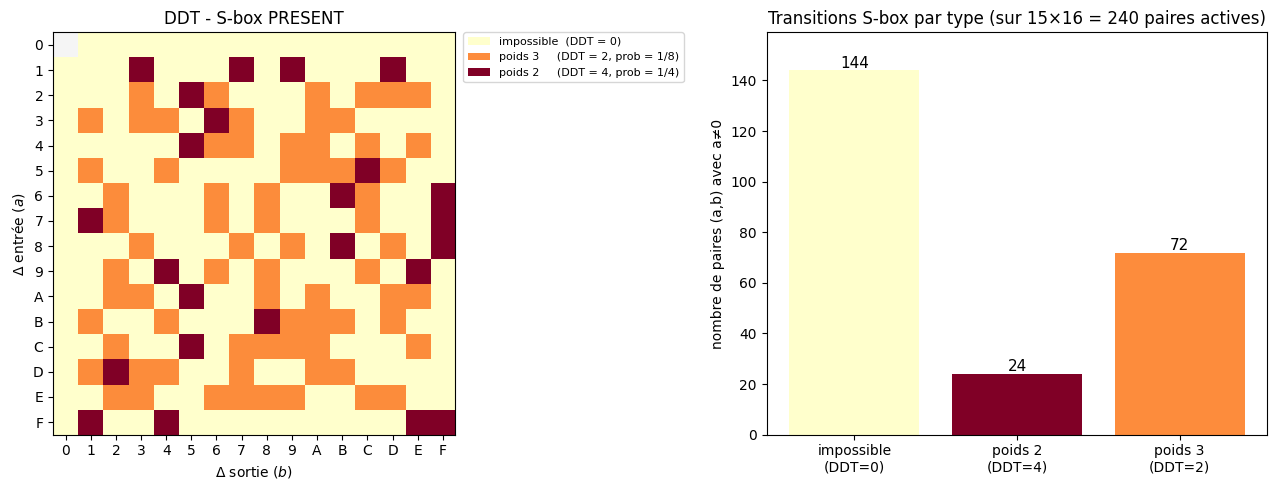

MDP = 4/16 = 1/4  =>  poids min par S-box active = 2
Transitions actives : 96  (dont 72 lourdes DDT=2)


In [4]:
from matplotlib.patches import Patch
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
cmap = plt.cm.YlOrRd
norm = plt.Normalize(vmin=0, vmax=4)
import numpy as np
ddt_display = np.array(DDT, dtype=float)
ddt_display[0, 0] = np.nan
cmap.set_bad("whitesmoke")
ax.imshow(ddt_display, cmap=cmap, norm=norm, aspect='equal')

ax.set_xticks(range(16)); ax.set_xticklabels([f'{i:X}' for i in range(16)])
ax.set_yticks(range(16)); ax.set_yticklabels([f'{i:X}' for i in range(16)])
ax.set_xlabel('$\\Delta$ sortie ($b$)')
ax.set_ylabel('$\\Delta$ entrée ($a$)')
ax.set_title('DDT - S-box PRESENT')

ax.legend(handles=[
    Patch(facecolor=cmap(norm(0)), label='impossible  (DDT = 0)'),
    Patch(facecolor=cmap(norm(2)), label='poids 3     (DDT = 2, prob = 1/8)'),
    Patch(facecolor=cmap(norm(4)), label='poids 2     (DDT = 4, prob = 1/4)'),
], fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

impossible = sum(1 for a in range(1, 16) for b in range(16) if DDT[a][b] == 0)
w2_count   = sum(1 for a in range(1, 16) for b in range(16) if DDT[a][b] == 4)
w3_count   = sum(1 for a in range(1, 16) for b in range(16) if DDT[a][b] == 2)

ax2 = axes[1]
bars = ax2.bar(
    ['impossible\n(DDT=0)', 'poids 2\n(DDT=4)', 'poids 3\n(DDT=2)'],
    [impossible, w2_count, w3_count],
    color=[cmap(norm(0)), cmap(norm(4)), cmap(norm(2))]
)
for bar, val in zip(bars, [impossible, w2_count, w3_count]):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, str(val),
             ha='center', fontsize=11)
ax2.set_ylabel('nombre de paires (a,b) avec a≠0')
ax2.set_title('Transitions S-box par type (sur 15×16 = 240 paires actives)')
ax2.set_ylim(0, max(impossible, w2_count, w3_count) + 15)

plt.tight_layout()
plt.show()
print(f"MDP = {DDT[1:].max()}/16 = 1/4  =>  poids min par S-box active = 2")
print(f"Transitions actives : {w2_count + w3_count}  (dont {w3_count} lourdes DDT=2)")


### 2.b - Encodage SAT

Un chemin différentiel sur $R$ tours est un tuple $(\Delta_0, \Delta_1, \ldots, \Delta_R)$ où chaque $\Delta_r$ est un vecteur de 64 bits. Pour chaque S-box $s$ au tour $r$, la paire (entrée, sortie) doit vérifier $\text{DDT}[a][b] > 0$.

L'approche consiste à encoder chaque contrainte $\text{DDT}[a][b] = 0$ comme une clause SAT interdisant l'affectation $(\text{entrée}=a, \text{sortie}=b)$. Un solveur SAT (CaDiCaL ou Kissat) peut alors trouver un chemin valide ou prouver qu'il n'en existe pas.

#### Variables SAT

Trois familles de variables booléennes sont introduites :

| Variable | Formule | Sémantique |
|---|---|---|
| `diff_var(r, i)` | $1 + r \cdot 64 + i$ | bit $i$ de $\Delta_r$ |
| `active_var(R, r, s)` | offset + $r \cdot 16 + s$ | 1 si la S-box $s$ au tour $r$ est active ($\Delta \neq 0$) |
| `heavy_var(R, r, s)` | offset + $R \cdot 16 + r \cdot 16 + s$ | 1 si la transition a DDT=2 (poids 3 au lieu de 2) |

Le poids total d'un chemin vaut $\sum_s 2 \cdot \text{active} + \text{heavy}$, ce qui permet d'exprimer une contrainte pseudo-booléenne `atmost` sur le poids total.

#### Optimisation : Quine-McCluskey (QM)

L'approche naïve génère une clause par paire invalide $(a, b)$ avec $\text{DDT}[a][b] = 0$. Sur 8 bits (4 pour $a$, 4 pour $b$), cela représente environ 160 clauses par S-box. Le calcul devient alors trop long à partir de R > 10 (environ 3h).

L'algorithme de **Quine-McCluskey** réduit ce nombre en regroupant plusieurs minterms invalides en un seul *prime implicant* : si deux minterms ne diffèrent que d'un seul bit et qu'aucun minterm valide ne se trouve dans leur voisinage, ils peuvent être fusionnés en un terme avec ce bit en « don't care ». Le processus est répété jusqu'à saturation, puis un sous-ensemble minimal de prime implicants est sélectionné pour couvrir tous les minterms invalides.

Par exemple, si $(a=\texttt{0001}, b=\texttt{0011})$ et $(a=\texttt{0001}, b=\texttt{0111})$ sont tous les deux invalides, ils sont fusionnés en $a=\texttt{0001}, b=\texttt{\_011}$ - une seule clause au lieu de deux.


In [5]:
# Comparaison : encodage naïf et QM
naive_count = sum(1 for a in range(16) for b in range(16) if DDT[a][b] == 0)
qm_8bit  = len(_SBOX_PI_TEMPLATES)
qm_10bit = len(_SBOX_WEIGHT_TEMPLATES)

print(f"Encodage naïf            : {naive_count:3d} clauses / S-box")
print(f"QM 8-bit  (build_model)  : {qm_8bit:3d} clauses / S-box  (gain ×{naive_count/qm_8bit:.1f})")
print(f"QM 10-bit (weighted)     : {qm_10bit:3d} clauses / S-box")
print()
# CNF sizes for R=1..5
print(f"{'R':>3}  {'vars':>6}  {'clauses (build_model)':>22}  {'clauses (weighted)':>20}")
print("-" * 58)
for r in range(1, 6):
    m  = build_model(r)
    mw = build_weighted_model(r)
    print(f"{r:>3}  {m.nv:>6}  {len(m.clauses):>22}  {len(mw.clauses):>20}")

Encodage naïf            : 159 clauses / S-box
QM 8-bit  (build_model)  :  41 clauses / S-box  (gain ×3.9)
QM 10-bit (weighted)     :  64 clauses / S-box

  R    vars   clauses (build_model)    clauses (weighted)
----------------------------------------------------------
  1     144                     738                  1026
  2     224                    1474                  2050
  3     304                    2210                  3074
  4     384                    2946                  4098
  5     464                    3682                  5122


**Nous avons donc maintenant un modèle complet et (relativement) optimisé. Il ne nous manque plus qu'un algorithme de recherche efficace.**

### 2.c - Algorithmes de recherche

Deux algorithmes successifs exploitent le modèle CNF pour calculer les bornes optimales.

**Algorithme 1 - S-boxes actives minimales** (`find_min_active_sbox`)

Une **recherche binaire** est effectuée sur $k$ : à chaque itération, la contrainte `CardEnc.atmost(active_vars, bound=k)` est ajoutée au CNF de base, encodée via un **littéral d'hypothèse** (*assumption*) pour pouvoir être retirée à l'itération suivante sans reconstruire le problème. Complexité : $O(\log(16R))$ appels SAT.

**Algorithme 2 - Poids minimum** (`find_min_trail_weight`)

1. On calcule $k^* = \text{min\_active}(R)$, ce qui donne la borne inférieure $W_{\min} \geq 2k^*$ (et $W_{\min} \geq W_{\min}(R{-}1) + 2$ puisque chaque tour supplémentaire contribue au moins 2).
2. Une **recherche linéaire ascendante** teste $W = W_{\text{lo}}, W_{\text{lo}}+1, \ldots$ en ajoutant `PBEnc.atmost(lits, weights, bound=W)` jusqu'à obtenir SAT.

La contrainte pseudo-booléenne encode $\sum_{s,r} 2 \cdot a_{s,r} + h_{s,r} \leq W$, avec $a_{s,r}$ = `active_var` (poids 2) et $h_{s,r}$ = `heavy_var` (poids supplémentaire 1 pour les transitions DDT=2).

La recherche linéaire est préférée à la recherche binaire car **CaDiCaL** accumule des clauses apprises entre les itérations, accélérant chaque appel suivant. Kissat, en revanche, crée un solveur frais à chaque itération.


#### Optimisation de la borne inférieure

**Lemme.** Pour PRESENT, $w_{\min}(R) \geq w_{\min}(R-1) + 2$ pour tout $R \geq 2$.

*Preuve.* Soit une trajectoire optimale $\Delta_0 \to \cdots \to \Delta_R$ de poids $w_{\min}(R)$, avec $\Delta_0 \neq 0$. Le préfixe $\Delta_0 \to \cdots \to \Delta_{R-1}$ a un poids $\geq w_{\min}(R-1)$. Il suffit donc de montrer que le dernier tour contribue $\geq 2$, c'est-à-dire que $\Delta_{R-1} \neq 0$.

La S-box de PRESENT étant bijective, $\Delta X = 0 \Leftrightarrow \Delta Y = 0$ (Wei et al., ePrint 2012/214, Lemme 6). Le `pLayer` et l'`AddRoundKey` préservent la nullité. Si $\Delta_{R-1} = 0$, alors par récurrence arrière $\Delta_0 = 0$ — contradiction. Donc $\Delta_{R-1} \neq 0$, au moins une S-box est active au tour $R$, et contribue un poids $\geq 2$. □

## 3 - Résultats

Les résultats sont présentés en trois parties : le nombre minimum de S-boxes actives, le poids minimum des chemins différentiels, puis l'extraction d'un chemin optimal. Pour $R \leq 8$, les calculs s'exécutent directement dans le notebook. Pour les valeurs plus grandes, les résultats sont mis en cache.


### 3.a - S-boxes actives minimales

Le nombre de S-boxes actives dans un chemin différentiel fournit une **borne inférieure sur le poids** : chaque S-box active contribue au moins 2, la probabilité maximale de la DDT étant 4/16 = 1/4. Minimiser ce nombre est donc une première étape avant de rechercher le poids exact.

La recherche binaire décrite en 2.c est appliquée avec CaDiCaL. Les temps de calcul croissent régulièrement avec $R$, avec quelques irrégularités (par exemple $R=28$ se résout plus vite que $R=27$), probablement dues aux clauses apprises par le solveur qui varient selon l'instance.


In [6]:
# Calcul du nombre minimal de S-Boxe active pour R=1..6
print(f"{'R':>3}  {'min_active':>10}  {'temps':>8}")
print("-" * 26)
for r in range(1, 7):
    t0 = time.time()
    k, _ = find_min_active_sbox(r, solver="cadical", return_trail=True)
    t = time.time() - t0
    print(f"{r:>3}  {k:>10}  {t:>7.3f}s")

  R  min_active     temps
--------------------------
  1           1    0.002s
  2           2    0.003s
  3           4    0.008s
  4           6    0.041s
  5          10    0.338s
  6          12    0.552s


In [7]:
# Résultats complets (CaDiCaL, R=1..31)
# Temps total : environ 1h. Le calcul pouvant être parallélisé car les résultats sont indépendants les uns des autres,
# le temps réel est plutôt de 20 minutes.
results = {
     1: ( 1,   0.004),  2: ( 2,   0.007),  3: ( 4,   0.010),  4: ( 6,   0.043),
     5: (10,   0.320),  6: (12,   0.559),  7: (14,   1.260),  8: (16,   2.744),
     9: (18,   4.022), 10: (20,   6.499), 11: (22,   8.900), 12: (24,  10.635),
    13: (26,  15.907), 14: (28,  20.555), 15: (30,  31.869), 16: (32,  49.165),
    17: (34,  66.990), 18: (36,  76.498), 19: (38,  79.118), 20: (40,  88.874),
    21: (42, 107.582), 22: (44, 109.953), 23: (46, 169.297), 24: (48, 203.690),
    25: (50, 212.520), 26: (52, 339.922), 27: (54, 393.231), 28: (56, 324.362),
    29: (58, 348.857), 30: (60, 468.026), 31: (62, 350.690),
}

print(f"{'R':>3}  {'min_active':>10}  {'borne inf poids':>16}  {'temps':>10}")
print("-" * 46)
for r, (k, t) in results.items():
    print(f"{r:>3}  {k:>10}  {2*k:>16}  {t:>9.3f}s")

print()
print(f"min_active(R) = 2R pour R ≥ 2  (sauf R=1 où min_active=1)")
print(f"Temps total : {sum(t for _, t in results.values()):.1f}s")


  R  min_active   borne inf poids       temps
----------------------------------------------
  1           1                 2      0.004s
  2           2                 4      0.007s
  3           4                 8      0.010s
  4           6                12      0.043s
  5          10                20      0.320s
  6          12                24      0.559s
  7          14                28      1.260s
  8          16                32      2.744s
  9          18                36      4.022s
 10          20                40      6.499s
 11          22                44      8.900s
 12          24                48     10.635s
 13          26                52     15.907s
 14          28                56     20.555s
 15          30                60     31.869s
 16          32                64     49.165s
 17          34                68     66.990s
 18          36                72     76.498s
 19          38                76     79.118s
 20          40                80

*La commande utilisée est:* 
```sh
uv run python3 -m present_sat --active --rmax 31
```

### 3.b - Poids minimum des chemins différentiels

Une fois le nombre minimum de S-boxes actives connu, on cherche le **poids minimum** réel d'un chemin sur $R$ tours, qui correspond à la meilleure probabilité différentielle atteignable.

On sait que $w_{\min}(R) \geq 2 \times \text{min\_active}(R)$, mais cette borne n'est pas toujours atteinte. Dans certains cas, la structure du chiffrement force au moins une transition DDT=2 (de poids 3 au lieu de 2), créant un **écart** entre la borne et le minimum réel.

C'est ce qu'on observe à partir de $R=10$ : le poids minimum est 41 alors que $2 \times 20 = 40$. Cet écart s'amplifie avec $R$ - il atteint 8 à $R=22$.

**Résultat principal :** dès $R=15$, $w_{\min} = 66 > 64$. Toute attaque différentielle sur 15 tours ou plus nécessite plus de $2^{65}$ paires de textes clairs - ce qui dépasse la taille de l'espace des textes clairs. PRESENT est donc résistant à la cryptanalyse différentielle à partir de 15 tours.

Les calculs pour $R > 10$ peuvent prendre de quelques minutes à plusieurs heures ; les résultats sont mis en cache ci-dessous.


In [8]:
import time
# Calcul live pour R=1..10
# Environ 20s d'éxécution
print(f"{'R':>3} | {'2*min_active_sbox':17} | {'min_weight':>10} | {'temps':>8}  | {'gap':>3}")
print("-" * 55)
for r in range(1, 11):
    t0 = time.time()
    w = find_min_trail_weight(r)
    t = time.time() - t0
    bound = 2 * ACTIVE_BOUNDS[r]
    gap = w - bound
    print(f"{r:>3} | {bound:>17} | {w:>10} | {t:>8.3f}s | {gap:>3}  {'<' if gap else ''}")

  R | 2*min_active_sbox | min_weight |    temps  | gap
-------------------------------------------------------
  1 |                 2 |          2 |    0.002s |   0  
  2 |                 4 |          4 |    0.008s |   0  
  3 |                 8 |          8 |    0.045s |   0  
  4 |                12 |         12 |    0.079s |   0  
  5 |                20 |         20 |    0.155s |   0  
  6 |                24 |         24 |    0.804s |   0  
  7 |                28 |         28 |    0.821s |   0  
  8 |                32 |         32 |    1.357s |   0  
  9 |                36 |         36 |    4.024s |   0  
 10 |                40 |         41 |   12.351s |   1  <


In [9]:
with open('benchmark.json', 'r') as f:
    b = json.load(f)
    print(f"{'R':>3}  {'min_active':>10}  {'2*active':>8}  {'min_weight':>10}  {'gap':>4}  {'temps':>11}")
    print("-" * 56)

    r_secure = sys.maxsize
    w_secure = None
    total_time = 0

    for r in sorted(b['min_weight_kissat_opti'], key=int):
        row = b['min_weight_kissat_opti'][r]
        a = b['min_active_cadical'][r]['min_active']
        w = row['min_weight']
        gap = w - 2 * a

        t = row['time']
        total_time += t

        if w > 64 and int(r) < r_secure:
            marker = "  <- seuil w > 64"
            w_secure = w
            r_secure = int(r)

        print(f"{r:>3}  {a:>10}  {2*a:>8}  {w:>10}  {gap:>4}  {t:>10.3f}s")

    print()
    print(f"Seuil de sécurité atteint à R={r_secure}  (w_min={w_secure} > 64)")
    print(f"Temps total de calcul : {total_time/3600:.1f}h")


  R  min_active  2*active  min_weight   gap        temps
--------------------------------------------------------
  1           1         2           2     0       0.006s
  2           2         4           4     0       0.011s
  3           4         8           8     0       0.052s
  4           6        12          12     0       0.088s
  5          10        20          20     0       0.170s
  6          12        24          24     0       1.281s
  7          14        28          28     0       0.880s
  8          16        32          32     0       1.412s
  9          18        36          36     0       4.379s
 10          20        40          41     1      12.911s
 11          22        44          46     2     116.060s
 12          24        48          52     4      77.303s
 13          26        52          56     4     120.685s
 14          28        56          62     6     453.334s
 15          30        60          66     6     373.606s
 16          32        64      

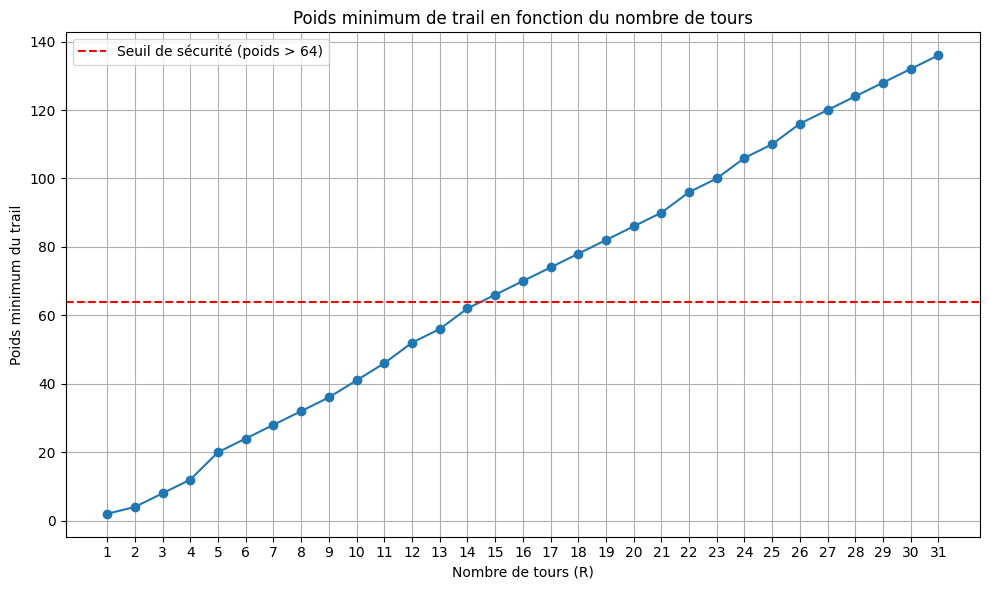

In [10]:
with open('benchmark.json', 'r') as f:
    b = json.load(f)

rounds = []
min_weights = []
for r in sorted(b['min_weight_kissat_opti'], key=int):
    row = b['min_weight_kissat_opti'][r]
    w = row['min_weight']
    rounds.append(int(r))
    min_weights.append(w)
plt.figure(figsize=(10, 6))
plt.plot(rounds, min_weights, marker='o')
plt.axhline(64, color='red', linestyle='--', label='Seuil de sécurité (poids > 64)')
plt.title('Poids minimum de trail en fonction du nombre de tours')
plt.xlabel('Nombre de tours (R)')
plt.ylabel('Poids minimum du trail')
plt.xticks(rounds)
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

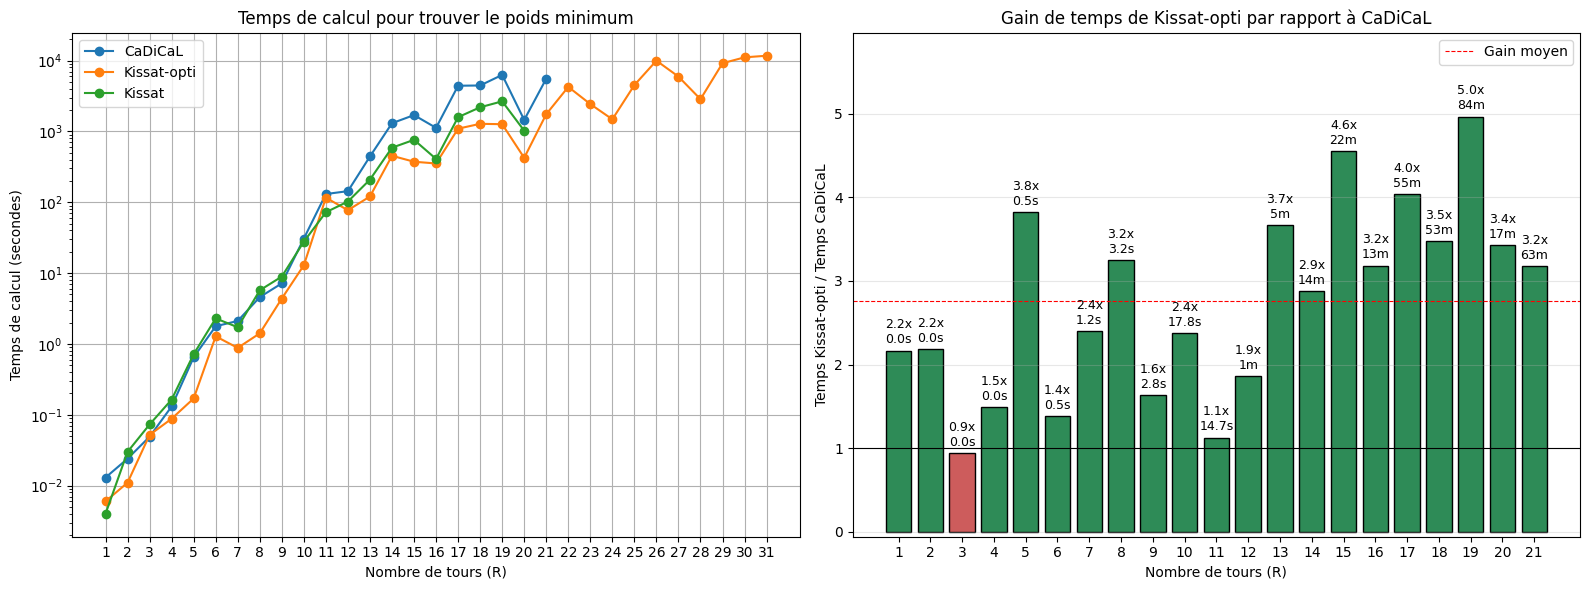

In [11]:
import json
import matplotlib.pyplot as plt
import numpy as np

with open('benchmark.json') as f:
    b = json.load(f)

fmt = lambda s: f"{s/60:.0f}m" if s >= 60 else f"{s:.1f}s"

r, tc, tko, tk, df, ds = [], [], [], [], [], []
for rk in sorted(b['min_weight_kissat_opti'], key=int):
    ro = b['min_weight_kissat_opti'][rk]
    rc = b['min_weight_cadical'].get(rk, {'time': None})
    rk = int(rk)
    
    df.append(rc['time'] / ro['time'] if rc['time'] else None)
    ds.append(rc['time'] - ro['time'] if rc['time'] else None)
    
    r.append(rk)
    tc.append(rc['time'])
    tko.append(ro['time'])
    tk.append(b['min_weight_kissat'].get(str(rk), {}).get('time'))

rd = [x for x, d in zip(r, df) if d]
df = [d for d in df if d]
ds = [s for s in ds if s]
c = ['seagreen' if d > 1 else 'indianred' for d in df]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(r, tc, 'o-', label='CaDiCaL')
ax1.plot(r, tko, 'o-', label='Kissat-opti')
ax1.plot(r, tk, 'o-', label='Kissat')
ax1.set(title='Temps de calcul pour trouver le poids minimum', 
        xlabel='Nombre de tours (R)', ylabel='Temps de calcul (secondes)',
        xticks=r, yscale='log')
ax1.grid(), ax1.legend()

bars = ax2.bar(rd, df, color=c, edgecolor='black')
ax2.axhline(1, color='black', linewidth=0.8)
ax2.axhline(np.mean(df), color='red', linestyle='--', linewidth=0.8, label='Gain moyen')

for bar, d, s in zip(bars, df, ds):
    h = bar.get_height()
    ax2.annotate(f"{d:.1f}x\n{fmt(abs(s))}", 
                 xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 3 if h > 0 else -3), textcoords='offset points',
                 ha='center', va=('bottom' if h > 0 else 'top'), fontsize=9)

ax2.set_ylim(min(df)-1, max(df)+1)
ax2.set(title='Gain de temps de Kissat-opti par rapport à CaDiCaL',
        xlabel='Nombre de tours (R)', ylabel='Temps Kissat-opti / Temps CaDiCaL',
        xticks=rd)
ax2.grid(axis='y', alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()

### 3.c - Extraction d'un chemin différentiel optimal

Lorsque le solveur retourne SAT pour un poids $W$, son modèle (liste de littéraux positifs/négatifs) encode l'intégralité du chemin différentiel. La fonction `decode_trail` lit les variables `diff_var(r, i)` pour reconstruire les $R+1$ mots de 64 bits $\Delta_0, \ldots, \Delta_R$.

Pour valider le chemin extrait, on vérifie que pour chaque S-box $s$ et chaque tour $r$, la paire (nibble d'entrée, nibble de sortie après P-layer) satisfait bien $\text{DDT} > 0$. La sortie après P-layer est calculée comme suit :
$$b_j = \text{bit}_{P[4s+j]}(\Delta_{r+1}), \quad j = 0,\ldots,3$$

Le poids réel du chemin est ensuite calculé à partir des variables `active_var` et `heavy_var` du modèle : $w = \sum_{s,r} 2 \cdot a_{s,r} + h_{s,r}$.


In [12]:
R_vis = 6
t0 = time.time()
W_vis, trail = find_min_trail_weight(R_vis, return_trail=True, solver="cadical")
elapsed = time.time() - t0

print(f"Trail optimal - R={R_vis}, poids W={W_vis}  ({elapsed:.3f}s)\n")
print(f"{'Tour':>6} | {'Δ_r':^18}")
print("-" * 27)

weight = trail_weight(trail)

for i, delta in enumerate(trail):
    print(f"{i:>6} | {delta:#018x}")

print(f"\nvalidate_trail  : {'ok' if validate_trail(trail, R_vis) else 'INVALIDE'}")
print(f"S-boxes actives : {trail_active_sboxes(trail)}")
print(f"poids total     : {weight}  (attendu {W_vis})")
print(f"probabilité     : 2^(-{weight})")

Trail optimal - R=6, poids W=24  (0.307s)

  Tour |        Δ_r        
---------------------------
     0 | 0x0007000000000007
     1 | 0x0000000000001001
     2 | 0x0009000000000009
     3 | 0x0000100100000000
     4 | 0x0000000009000900
     5 | 0x0000004400000000
     6 | 0x0000030000000300

validate_trail  : ok
S-boxes actives : 12
poids total     : 24.0  (attendu 24)
probabilité     : 2^(-24.0)


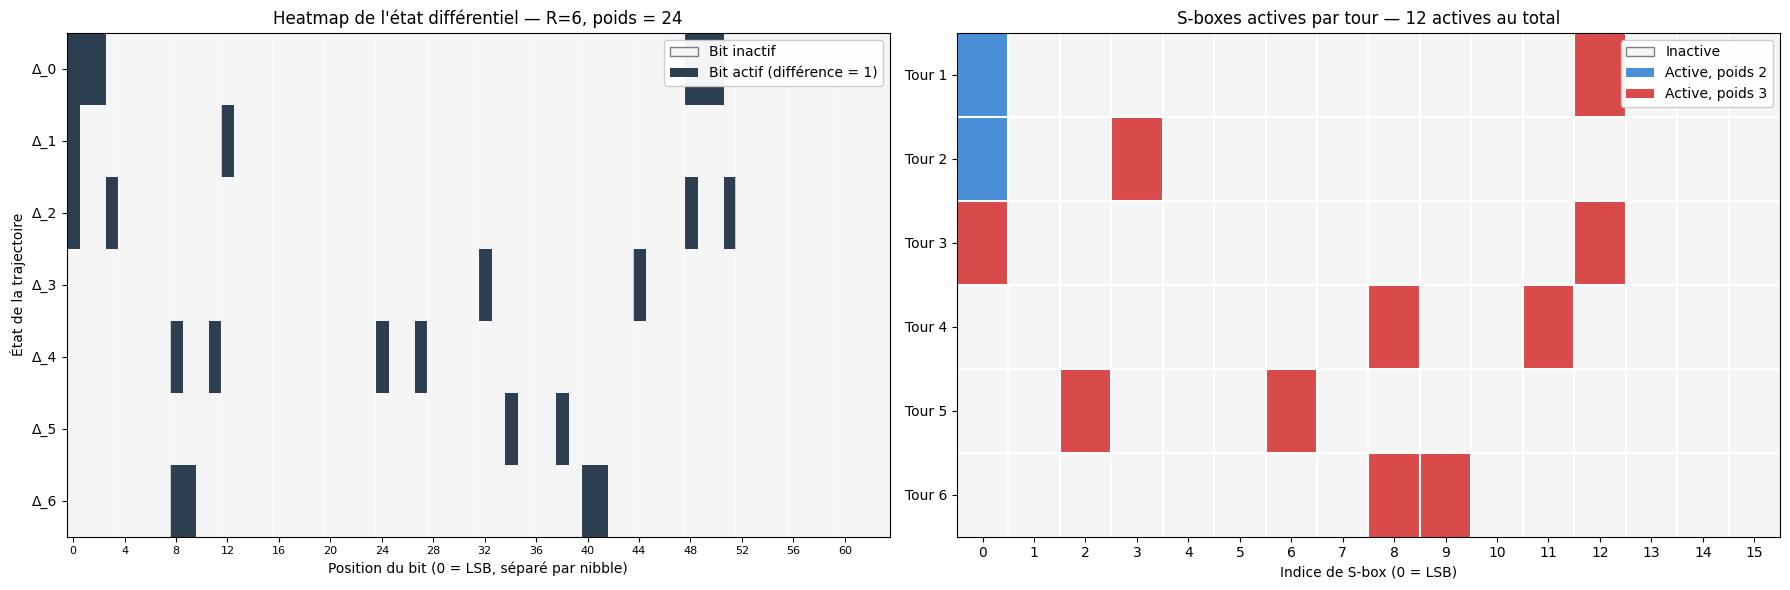

In [13]:

def out_nibble(s, d_out):
    return (d_out >> (4 * s)) & 0xF
# =======================================================
# Préparation des données
# =======================================================

# Matrice 1 : état bit par bit (R+1 lignes × 64 colonnes)
# 0 = bit inactif, 1 = bit actif
state_bits = np.zeros((R_vis + 1, 64), dtype=int)
for r in range(R_vis + 1):
    for j in range(64):
        state_bits[r, j] = (trail[r] >> j) & 1

# Matrice 2 : statut des S-boxes par tour (R × 16)
# 0 = inactive, 1 = active poids 2, 2 = active poids 3
sbox_status = np.zeros((R_vis, 16), dtype=int)
for r in range(R_vis):
    delta_in = trail[r]
    delta_out = trail[r + 1]
    for s in range(16):
        a = (delta_in >> (4 * s)) & 0xF
        if a == 0:
            sbox_status[r, s] = 0
        else:
            b = out_nibble(s, delta_out)
            sbox_status[r, s] = 1 if DDT[a][b] == 4 else 2

# =======================================================
# Affichage côte à côte
# =======================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# -------- Plot 1 : Heatmap de l'état bit par bit --------

cmap1 = plt.matplotlib.colors.ListedColormap(['#f5f5f5', '#2c3e50'])
ax1.imshow(state_bits, cmap=cmap1, aspect='auto', interpolation='nearest')

# Séparation visuelle des nibbles (tous les 4 bits)
for x in range(4, 64, 4):
    ax1.axvline(x - 0.5, color='white', linewidth=0.8, alpha=0.7)

ax1.set_xticks(range(0, 64, 4))
ax1.set_xticklabels([f"{i*4}" for i in range(16)], fontsize=8)
ax1.set_yticks(range(R_vis + 1))
ax1.set_yticklabels([f"Δ_{r}" for r in range(R_vis + 1)])
ax1.set_xlabel("Position du bit (0 = LSB, séparé par nibble)")
ax1.set_ylabel("État de la trajectoire")
ax1.set_title(f"Heatmap de l'état différentiel — R={R_vis}, poids = {W_vis}")

legend1 = [
    Patch(facecolor='#f5f5f5', edgecolor='gray', label='Bit inactif'),
    Patch(facecolor='#2c3e50', label='Bit actif (différence = 1)'),
]
ax1.legend(handles=legend1, loc='upper right', framealpha=0.95)

# -------- Plot 2 : S-boxes actives par tour --------

cmap2 = plt.matplotlib.colors.ListedColormap(['#f5f5f5', '#4a90d9', '#d94a4a'])
ax2.imshow(sbox_status, cmap=cmap2, vmin=0, vmax=2, aspect='auto')

# Quadrillage entre cases
ax2.set_xticks(np.arange(16) - 0.5, minor=True)
ax2.set_yticks(np.arange(R_vis) - 0.5, minor=True)
ax2.grid(which='minor', color='white', linewidth=1.5)
ax2.tick_params(which='minor', length=0)

ax2.set_xticks(range(16))
ax2.set_xticklabels(range(16))
ax2.set_yticks(range(R_vis))
ax2.set_yticklabels([f"Tour {r+1}" for r in range(R_vis)])
ax2.set_xlabel("Indice de S-box (0 = LSB)")
ax2.set_title(f"S-boxes actives par tour — {sum(sum(row > 0) for row in sbox_status)} actives au total")

legend2 = [
    Patch(facecolor='#f5f5f5', edgecolor='gray', label='Inactive'),
    Patch(facecolor='#4a90d9', label='Active, poids 2'),
    Patch(facecolor='#d94a4a', label='Active, poids 3'),
]
ax2.legend(handles=legend2, loc='upper right', framealpha=0.95)

plt.tight_layout()
plt.savefig(f"trail_R{R_vis}_views12.png", dpi=150, bbox_inches='tight')
plt.show()

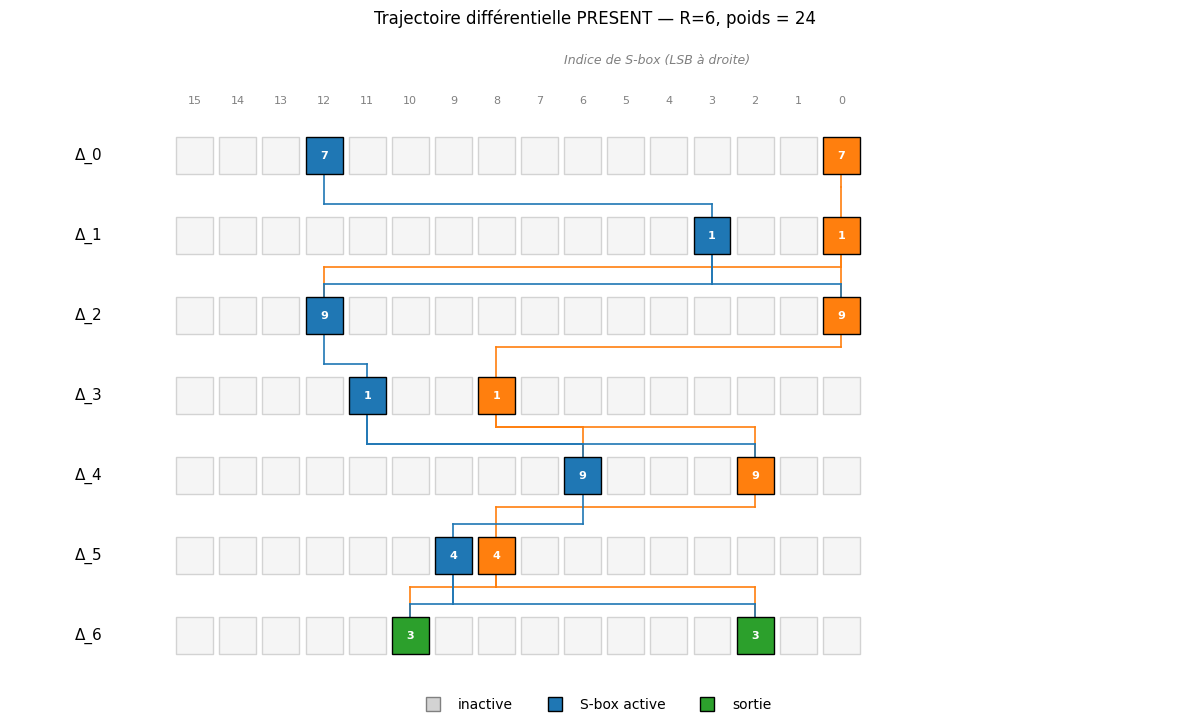

In [17]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

def out_nibble(s, d_out):
    return (d_out >> (4 * s)) & 0xF

P_COL = plt.get_cmap('tab10').colors
SQ, ROW, COL, BAND = 0.6, 1.3, 0.7, (1.3 - 0.6) * 0.8

a, w, i = [], [], []
for r in range(R_vis):
    d_in, d_out = trail[r], trail[r + 1]
    al, wd, id = [], {}, {}
    for s in range(16):
        nib = (d_in >> (4 * s)) & 0xF
        if nib:
            al.append(s)
            id[s], b = nib, out_nibble(s, d_out)
            wd[s] = 2 if DDT[nib][b] == 4 else 3
    a.append(al), w.append(wd), i.append(id)

fo = {s: (trail[R_vis] >> (4*s)) & 0xF for s in range(16) if (trail[R_vis] >> (4*s)) & 0xF}

xp = lambda s: (15 - s) * COL
yp = lambda r: -r * ROW
gc = lambda r, s: P_COL[sorted(a[r], key=xp).index(s) % 10]

fig, ax = plt.subplots(figsize=(12, 8))

for r in range(R_vis):
    for s_src in a[r]:
        sa = sorted(a[r], key=xp)
        idx, n, offset = sa.index(s_src), len(a[r]), -BAND/2 + (sa.index(s_src)+0.5)*(BAND/len(a[r]))
        y1, y2, ym, x1, col = yp(r) - SQ/2, yp(r+1) + SQ/2, (yp(r)-SQ/2 + yp(r+1)+SQ/2)/2 + offset, xp(s_src), gc(r, s_src)
        
        for k in range(4):
            if (trail[r+1] >> P[4*s_src + k]) & 1:
                s_dst = P[4*s_src + k] // 4
                if (r+1 < R_vis and s_dst in a[r+1]) or (r+1 == R_vis and s_dst in fo):
                    x2 = xp(s_dst)
                    ax.plot([x1, x1], [y1, ym], color=col, lw=1.2, zorder=1)
                    ax.plot([x1, x2], [ym, ym], color=col, lw=1.2, zorder=1)
                    ax.plot([x2, x2], [ym, y2], color=col, lw=1.2, zorder=1)

for r in range(R_vis):
    for s in range(16):
        x, y = xp(s), yp(r)
        if s in a[r]:
            ax.add_patch(Rectangle((x-SQ/2, y-SQ/2), SQ, SQ, fc=gc(r,s), ec='black', zorder=3))
            ax.text(x, y, f"{i[r][s]:X}", ha='center', va='center', fontsize=8, color='white', fontweight='bold', zorder=4)
        else:
            ax.add_patch(Rectangle((x-SQ/2, y-SQ/2), SQ, SQ, fc='whitesmoke', ec='lightgray', zorder=3))

for s in range(16):
    x, y = xp(s), yp(R_vis)
    if s in fo:
        ax.add_patch(Rectangle((x-SQ/2, y-SQ/2), SQ, SQ, fc='C2', ec='black', zorder=3))
        ax.text(x, y, f"{fo[s]:X}", ha='center', va='center', fontsize=8, color='white', fontweight='bold', zorder=4)
    else:
        ax.add_patch(Rectangle((x-SQ/2, y-SQ/2), SQ, SQ, fc='whitesmoke', ec='lightgray', zorder=3))

[ax.text(-1.5, yp(r), f"Δ_{r}", ha='right', va='center', fontsize=11) for r in range(R_vis+1)]
[ax.text(xp(s), 0.9, str(s), ha='center', va='center', fontsize=8, color='gray') for s in range(16)]

ax.text(7.5, 1.5, "Indice de S-box (LSB à droite)", ha='center', fontsize=9, color='gray', style='italic')
ax.set_title(f"Trajectoire différentielle PRESENT — R={R_vis}, poids = {W_vis}")
ax.set_xlim(-3, 16), ax.set_ylim(yp(R_vis) - 0.9, 2), ax.set_aspect('equal'), ax.axis('off')
ax.legend(handles=[Line2D([0],[0], marker='s', color='w', markerfacecolor=c, markeredgecolor=e, markersize=10, label=l) 
                   for c, e, l in [('lightgray','gray','inactive'), ('C0','black','S-box active'), ('C2','black','sortie')]],
          loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()
plt.savefig(f"trail_R{R_vis}.png", dpi=120, bbox_inches='tight')
plt.show()

### Analyse des chemins extraits

Les deux chemins optimaux extraits (R=3 et R=5) illustrent des propriétés structurelles de PRESENT.

**Structure des chemins.** Sur 3 tours, le chemin optimal ne fait intervenir qu'un petit nombre de composants non-linéaires actifs par tour - reflétant la contrainte d'optimisation (minimiser le poids). Le chemin sur 5 tours active davantage de composants par tour, mais leur nombre reste faible au regard des 16 S-boxes disponibles : la P-layer de PRESENT force la diffusion des différences, ce qui augmente mécaniquement le nombre de composants actifs d'un tour à l'autre.

**Poids et probabilité.** Chaque composant non-linéaire actif contribue au moins 2 au poids total (probabilité $\leq 2^{-2}$). Le poids croît donc au moins linéairement avec le nombre de tours. Les valeurs obtenues correspondent aux bornes inférieures connues dans la littérature (tableau 1.d), ce qui confirme l'optimalité des chemins trouvés par le solveur SAT.

**Absence de transitions lourdes (poids 3) pour R $\leq$ 9.** Les résultats du tableau 3.b montrent que $w_{\min}(R) = 2 \times a_{\min}(R)$ pour $R \leq 9$ : aucune transition ne contribue 3 au poids. Cela correspond aux transitions DDT=4, soit les plus probables parmi les transitions actives ($2^{-2}$ contre $2^{-3}$). Le solveur préfère naturellement ces transitions pour minimiser le poids global.

**Diffusion.** L'éclatement des différences d'un tour à l'autre est une conséquence directe de la P-layer, qui redistribue les bits de sortie de chaque S-box vers 16 S-boxes différentes à l'entrée du tour suivant. C'est cette propriété qui garantit la croissance rapide du nombre de composants actifs, et donc du poids, avec le nombre de tours.

### 3.d - Visualisations

Cette section présente une synthèse graphique des résultats :
- Évolution du nombre de S-boxes actives et du poids minimum en fonction de $R$
- Temps de résolution SAT en fonction de $R$ (croissance exponentielle)
- Carte du chemin différentiel optimal pour $R=5$ : chaque case représente une S-box, colorée selon son poids


NameError: name 'min_active_results' is not defined

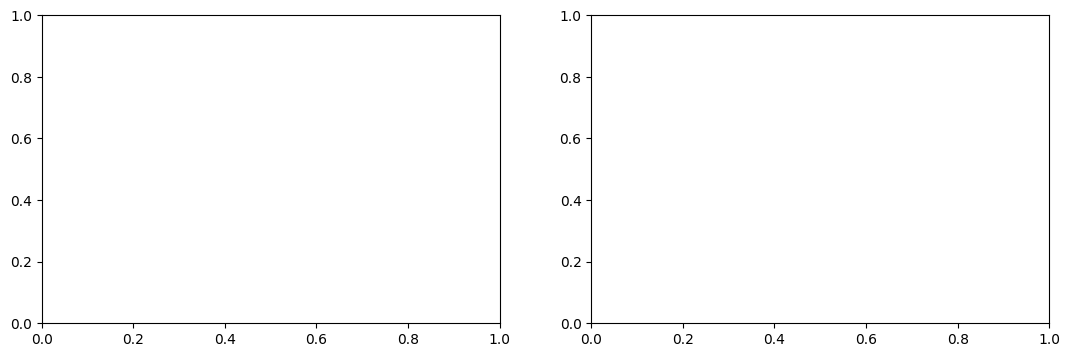

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
r_list = sorted(min_active_results)
ax.plot(r_list, [min_active_results[r]   for r in r_list], 'o-',  label='min_active')
ax.plot(r_list, [2*min_active_results[r] for r in r_list], '--', alpha=0.6, label='2 × min_active (borne inf poids)')
ax.plot(r_list, [min_weight_results[r]   for r in r_list], 's-', color='tomato', label='min_weight')
# Annoter le gap à R=10
r10 = 10
ax.annotate('gap=1\n(DDT=2 forcée)', xy=(r10, min_weight_results[r10]),
            xytext=(r10-1.5, min_weight_results[r10]+2),
            arrowprops=dict(arrowstyle='->', color='tomato'), fontsize=8, color='tomato')
ax.set_xlabel('tours R')
ax.set_ylabel('valeur')
ax.set_title('S-boxes actives vs poids du chemin optimal')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
ax.semilogy(r_list, [solve_times[r] for r in r_list], 'o-', color='steelblue')
ax.set_xlabel('tours R')
ax.set_ylabel('temps de résolution (s)')
ax.set_title('Temps SAT en fonction du nombre de tours (échelle log)')
ax.grid(alpha=0.3, which='both')
# Ligne de référence 60s
ax.axhline(y=60, color='tomato', linestyle='--', alpha=0.5, label='60s')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()
print(f"Temps R=10 : {solve_times[10]:.1f}s  |  Croissance approx. ×{solve_times[10]/solve_times[9]:.1f} par tour (R=9->10)")

NameError: name 'is_heavy' is not defined

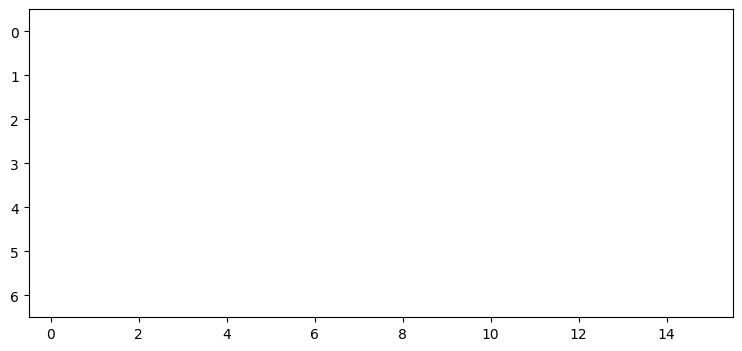

In [ ]:
# Carte du trail optimal R=5 - grille 16 S-boxes × (R+1) couches
fig, ax = plt.subplots(figsize=(15, 4))
ax.set_xlim(-0.5, 15.5)
ax.set_ylim(-0.5, R_vis + 0.5)
ax.set_aspect('equal')
ax.invert_yaxis()

for r in range(R_vis + 1):
    d = trail[r]
    for s in range(16):
        nibble = (d >> (4 * s)) & 0xF
        if r < R_vis:
            if is_heavy[r][s]:
                color = 'tomato'
            elif is_active[r][s]:
                color = 'steelblue'
            else:
                color = '#eeeeee'
        else:
            color = '#aaccee' if nibble else '#eeeeee'
        ax.add_patch(plt.Rectangle((s - 0.45, r - 0.45), 0.9, 0.9,
                                    fc=color, ec='#999999', lw=0.5))
        if nibble:
            fc = 'white' if color in ('steelblue', 'tomato') else '#333333'
            ax.text(s, r, f'{nibble:X}', ha='center', va='center', fontsize=9, color=fc, fontweight='bold')

ax.set_xticks(range(16))
ax.set_xticklabels([f'S{i}' for i in range(16)], fontsize=9)
ax.set_yticks(range(R_vis + 1))
ax.set_yticklabels([f'Δ{r}' for r in range(R_vis + 1)])
ax.set_title(f'Trail différentiel optimal - R={R_vis} tours, poids={W_vis} (prob = 2^-{W_vis})')
ax.legend(
    handles=[
        mpatches.Patch(fc='steelblue', label=f'S-box active poids 2 (DDT=4)'),
        mpatches.Patch(fc='tomato',    label=f'S-box active poids 3 (DDT=2)'),
        mpatches.Patch(fc='#eeeeee', ec='#999999', label='inactive'),
    ],
    loc='upper right', fontsize=9
)
plt.tight_layout()
plt.show()

## 4 - Conclusion

### Ce qu'on a fait

On a encodé la recherche de chemins différentiels de poids minimum sur PRESENT en SAT, avec deux optimisations principales :

1. **Encodage QM compact** - les clauses S-box sont calculées une seule fois via Quine-McCluskey sur l'espace 8 bits (ou 10 bits avec le poids), ce qui réduit le nombre de clauses d'un facteur ~10× par rapport à l'encodage naïf.
2. **Solveur incrémental** - CaDiCaL est conservé entre les itérations de la recherche ; les clauses apprises accélèrent chaque étape suivante sans reconstruction du problème.

### Résultats

| propriété | valeur |
|---|---|
| $\text{min\_active}(5)$ | 10 - confirme **Bogdanov et al., Theorem 1** |
| $\text{min\_weight}(R=1..9)$ | $= 2 \times \text{min\_active}$ - borne atteinte, aucune transition lourde |
| $\text{min\_weight}(10)$ | $41 > 40$ - une transition DDT=2 est inévitable |
| Seuil de sécurité | $R = 15$ - dès $R \geq 15$, $w_{\min} > 64$ |
| Temps de calcul ($R=10$) | $\sim 13$s - croissance exponentielle avec $R$ |

### Limites et perspectives

Le temps de résolution croît exponentiellement avec $R$, ce qui rend l'approche difficile à passer à l'échelle au-delà de $R \approx 25$ avec un solveur CDCL généraliste. Des approches plus adaptées existent :

- **DFS branch-and-bound avec PC1/PC2** (Kim et al., ToSC 2022) : bornes inférieures calculées inductivement, élagage par propagation - atteint $R=31$ en quelques secondes.
- **MILP** : relaxation linéaire des contraintes DDT, utilisée dans des outils comme CLAASP pour les chiffrements AES-like.

### Références

- Bogdanov et al. (2007). *PRESENT: An Ultra-Lightweight Block Cipher.* CHES 2007.
- Sun et al. (2014). *Automatic Security Evaluation and (Related-key) Differential Characteristic Search for Ciphers.* ASIACRYPT 2014.
- Biere (2021). *CaDiCaL, Kissat, Gimsatul - SAT Competition 2021.*
- Kim et al. (2022). *Accelerating the Search for the Best Differential Trails.* ToSC 2022.
